# KMOS — Rest-frame stacking of [OIII] / Hβ, grouped by galaxy

Builds on `kmos_stacked_showcase_group.ipynb` (cells 1–8 identical: one stack
per galaxy and band, multi-band galaxies grouped, all bands centred on Hα).

**Why.**  Hα is strong in YJ (z≈0.7) / H (z≈1.46), but [OIII] and Hβ of the
COSMOS galaxies fall at 0.81–0.90 µm in the IZ cubes, where the data are much
less sensitive — individually they are not detected.  Here we

1. take **redshift and line width from Hα** of the same galaxy,
2. extract the [OIII]/Hβ spectrum with **three methods** and compare them
   * **A** 5×5 box at the band's own centre (what the other notebooks do),
   * **B** 5×5 box at the Hα position (transferred via WCS),
   * **C** **optimal extraction**: spaxels weighted by the **Hα map** of the
     galaxy (from its Hα band, mapped onto the [OIII] cube via WCS) and by the
     pipeline noise cube **STAT** (1/σ², down-weights sky-line residuals),
3. shift every spectrum to the **rest frame** (z from Hα), normalise to its
   continuum (line flux in units of the continuum, i.e. equivalent width) and
   build an **inverse-variance weighted stack** per sample.

Samples: COSMOS (IZ), split by Hα strength, and SPT2040 + XMM2215 (YJ) as a
comparison where [OIII]/Hβ are in a sensitive band.

**Sections**
1–8. Load, stack per galaxy and band, group multi-band galaxies (as in the group showcase)
9. Configuration and helpers
10. Per-galaxy extraction (methods A/B/C) and rest-frame spectra
11. Stacks per sample, line fits, [OIII]/Hβ
12. Detail view per sample — stack, line zooms, individual spectra, methods
13. Summary — S/N per method and sample
14. Gallery — per galaxy: Hα weight map and rest-frame [OIII]/Hβ (A vs C)

In [1]:
import glob, os, csv, pathlib, warnings, re
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from astropy.io import fits

# ── DATA SOURCE SWITCH ────────────────────────────────────────────────────────
USE_EXTERNAL = True          # True  → use kmos_proc_server_comb/ (external combined cubes)
                              # False → use kmos_ob_proc_server/   (own reduced files)
COMB_BASE    = "kmos_proc_and_comb_server"

# ── paths ─────────────────────────────────────────────────────────────────────
BASE         = "kmos_ob_proc_server"
SUFFIX       = "_s_i_bkg2d_rv_tell.fits"
ECDFS_TABLE  = pathlib.Path("scripts") / "table_ifus_ECDFS 2.fits"
COSMOS_TABLE = pathlib.Path("scripts") / "table_ifus_COSMOS_Field_exptime.fits"

# ── extraction parameters ─────────────────────────────────────────────────────
APERTURE          = 5
EDGE_MARGIN       = 4
MAX_CENTER_OFFSET = 4.0

# ── Hα ───────────────────────────────────────────────────────────────────────
HA_REST      = 0.65628   # µm
SNR_WIN_HALF = 0.0025
SNR_CONT_IN  = 0.006
SNR_CONT_OUT = 0.022
SNR_MIN      = 2.0

# ── display ───────────────────────────────────────────────────────────────────
TOP_DETAIL   = 30          # galaxies in detail view
ZOOM_HALF    = 0.018      # ±µm around each line in zoom panels
HB_ZOOM_HALF = 0.012      # slightly narrower window for Hβ (often weaker)

PALETTE = [
    "#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400",
    "#16a085", "#2c3e50", "#e74c3c", "#2980b9", "#1abc9c",
    "#f39c12", "#7f8c8d", "#6c3483", "#1e8449", "#922b21",
    "#0e6655", "#784212", "#1b4f72", "#f1c40f", "#8e44ad",
    "#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#e74c3c",
    "#34495e", "#f39c12", "#2c3e50", "#d35400", "#16a085",
    "#2980b9", "#c0392b", "#27ae60", "#8e44ad", "#f1c40f",
    "#7f8c8d", "#1abc9c", "#e67e22", "#2c3e50", "#3498db",
    "#8e44ad", "#d35400", "#16a085", "#c03a2b", "#27ae60",
    "#922b21", "#1e8449", "#1b4f72", "#784212", "#0e6655",
]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── robust line S/N: scripts/line_snr.py ─────────────────────────────────────
import sys, importlib, pathlib
_SCRIPTS = str(pathlib.Path("scripts").resolve())
if _SCRIPTS not in sys.path:
    sys.path.insert(0, _SCRIPTS)
import line_snr as _lsnr
importlib.reload(_lsnr)
import kmos_sample as ks          # galaxy identity, z lookup, exposure time, stacking
importlib.reload(ks)
canonical_field = ks.canonical_field

# ── data helpers ──────────────────────────────────────────────────────────────
def wavelength_axis(hdr):
    cdelt = hdr.get("CDELT3", hdr.get("CD3_3", 1.0))
    return (np.arange(hdr["NAXIS3"]) + 1 - hdr["CRPIX3"]) * cdelt + hdr["CRVAL3"]

def active_ifus(hdul):
    result = []
    for i in range(1, 25):
        try:
            d = hdul[i].data
            if d is not None and np.ndim(d) == 3:
                result.append(i)
        except Exception:
            pass
    return result

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def aperture_spectrum(hdul, ifu, center, box=APERTURE, margin=EDGE_MARGIN):
    cube  = np.array(hdul[ifu].data)
    hdr   = hdul[ifu].header
    py, px = center
    h2    = box // 2
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch  = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid  = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(cube.shape[0], np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return wavelength_axis(hdr), spec

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def find_exposures(base=BASE, suffix=SUFFIX):
    result = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(base, "*", "science", f"*{suffix}"))):
        parts = path.replace("\\", "/").split("/")
        ob    = parts[-3]
        with fits.open(path) as h:
            band = h[0].header.get("HIERARCH ESO INS GRAT1 ID", "??")
        result[(ob, band)].append(path)
    return dict(result)

def ob_to_dpid(ob_name):
    """Convert OB folder name to dp_id format.
    'KMOS.2026-01-13T03-42-28.829' → 'KMOS.2026-01-13T03:42:28.829'
    """
    if 'T' not in ob_name:
        return ob_name
    date_part, time_part = ob_name.split('T', 1)
    parts = time_part.split('-', 2)
    if len(parts) == 3:
        return f"{date_part}T{parts[0]}:{parts[1]}:{parts[2]}"
    return ob_name

def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08):
    ha_obs = HA_REST * (1.0 + z)
    hp     = int(np.argmin(np.abs(wave - ha_obs)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid  = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im  = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape
    flat   = ha_im.ravel()
    order  = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), ha_im
    return ifu_center(cube), ha_im

def line_snr(wave, spec, z, line_rest,
             win_half=SNR_WIN_HALF, cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT,
             min_width_px=3):
    """Robust S/N via scripts/line_snr.py: Gaussian-fit line flux / error
    (spikes masked, LSF/velocity priors, correlated noise; see that file)."""
    return _lsnr.line_snr(wave, spec, z, line_rest, win_half=win_half,
                          cont_in=cont_in, cont_out=cont_out)

def ha_snr(wave, spec, z):
    return line_snr(wave, spec, z, HA_REST)

def narrowband_image(cube, wave, z, line_rest, margin=EDGE_MARGIN):
    lam_obs = line_rest * (1.0 + z)
    if not (wave.min() < lam_obs < wave.max()):
        return None
    hp      = int(np.argmin(np.abs(wave - lam_obs)))
    p0, p1  = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid   = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    return np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)

# ── emission lines ────────────────────────────────────────────────────────────
EMISSION_LINES = {
    "[OII]3727":    (0.37270, "#e377c2"),
    "Hβ":           (0.48627, "#1f77b4"),
    "[OIII]4959":   (0.49594, "#7fdbff"),
    "[OIII]5007":   (0.50082, "#17becf"),
    "Hα":           (0.65628, "#d62728"),
    "[NII]6583":    (0.65835, "#ff7f0e"),
    "[SII]6716":    (0.67163, "#9467bd"),
    "[SII]6731":    (0.67308, "#c5b0d8"),
}

# ── redshift catalogue ────────────────────────────────────────────────────────
_Z_TABLE, _Z_TYPE, _Z_QUALITY = {}, {}, {}
_Z_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
if _Z_CSV.exists():
    with open(_Z_CSV, newline="", encoding="utf-8") as _f:
        for _row in csv.DictReader(_f):
            if (_row.get("redshift") or "").strip():
                _key = (_row["field"].strip(), _row["arm_target_id"].strip())
                _Z_TABLE[_key] = float(_row["redshift"].strip())
                _Z_TYPE[_key]  = (_row.get("redshift_type") or "").strip()
                _q = (_row.get("quality") or "").strip()
                try:
                    _Z_QUALITY[_key] = float(_q)
                except (ValueError, TypeError):
                    _Z_QUALITY[_key] = np.nan
    print(f"Loaded {len(_Z_TABLE)} redshifts  "
          f"(spec: {sum(1 for v in _Z_TYPE.values() if v=='spec')}, "
          f"photo: {sum(1 for v in _Z_TYPE.values() if v=='photo')}, "
          f"cluster: {sum(1 for v in _Z_TYPE.values() if v=='cluster')})")
else:
    print(f"WARNING: {_Z_CSV} not found — emission lines will not be drawn")

# galaxy-level redshift lookup: exact (target list, id), else (survey region, id)
# — e.g. 'SPT2040_Halpha' is not in the CSV but its galaxies are.  scripts/kmos_sample.py
ZCAT = ks.RedshiftCatalog(_Z_CSV)
z_lookup = ZCAT.lookup
print(f"  → {len(ZCAT)} unique galaxies (survey region, target id) with a redshift")

def get_z_meta(hdul, ifu):
    hdr0  = hdul[0].header
    field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
    key   = f"ESO OCS ARM{ifu} NAME"
    tid   = str(hdr0.get(key) or hdr0.get(f"HIERARCH {key}") or "").strip()
    if not field or not tid:
        return None, "", np.nan
    zi = z_lookup(field, tid)
    return zi if zi is not None else (None, "", np.nan)

Loaded 178 redshifts  (spec: 161, photo: 1, cluster: 16)
  → 158 unique galaxies (survey region, target id) with a redshift


In [3]:
# ── Load FITS catalog tables → group_id lookup ─────────────────────────────────
# dpid_ifu_to_group[(dp_id, ifu)] = group_id
dpid_ifu_to_group = {}

for tbl_path in [ECDFS_TABLE, COSMOS_TABLE]:
    if not tbl_path.exists():
        print(f"WARNING: {tbl_path} not found")
        continue
    with fits.open(tbl_path) as hdul:
        t = hdul[1].data
        for i in range(len(t)):
            dpid_ifu_to_group[(t['dp_id'][i].strip(), int(t['ifu'][i]))] = int(t['group_id'][i])
    print(f"Loaded {len(t):,} rows from {tbl_path.name}")

print(f"Total catalog entries from tables: {len(dpid_ifu_to_group):,}")

# ── Fallback: build synthetic group_ids for fields not in the FITS tables ──────
# Fields like SPT2040 and XMM2215 have no ECDFS/COSMOS catalog table; assign
# synthetic group_ids (≥ 90000) from (field, arm_target_id) pairs found in Z_TABLE.
_synthetic_next = 90000
_field_tid_to_group = {}   # (field, arm_target_id) → synthetic group_id

for path in sorted(glob.glob(os.path.join(BASE, "*", "science", f"*{SUFFIX}"))):
    parts = path.replace("\\", "/").split("/")
    ob    = parts[-3]
    dpid  = ob_to_dpid(ob)
    with fits.open(path) as h:
        hdr0  = h[0].header
        field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
        if not field:
            continue
        for ifu in range(1, 25):
            if (dpid, ifu) in dpid_ifu_to_group:
                continue           # already covered by tables
            if ifu >= len(h):
                continue
            try:
                d = h[ifu].data
                if d is None or np.ndim(d) != 3:
                    continue
            except Exception:
                continue
            key_hdr = f"ESO OCS ARM{ifu} NAME"
            tid = str(hdr0.get(key_hdr) or hdr0.get(f"HIERARCH {key_hdr}") or "").strip()
            if not tid:
                continue
            k = (field, tid)
            if k not in _Z_TABLE:
                continue           # unknown target, skip
            if k not in _field_tid_to_group:
                _field_tid_to_group[k] = _synthetic_next
                _synthetic_next += 1
            dpid_ifu_to_group[(dpid, ifu)] = _field_tid_to_group[k]

if _field_tid_to_group:
    print(f"Added {len(_field_tid_to_group)} synthetic group_ids for targets not in catalog tables "
          f"(ids {90000}–{_synthetic_next - 1})")
    from collections import Counter
    field_counts = Counter(k[0] for k in _field_tid_to_group)
    for field, n in field_counts.most_common():
        print(f"  {field}: {n} targets")

print(f"Total catalog entries (incl. synthetic): {len(dpid_ifu_to_group):,}")

# Reverse map for diagnostics
group_to_dpids = defaultdict(list)
for (dpid, ifu), gid in dpid_ifu_to_group.items():
    group_to_dpids[gid].append((dpid, ifu))
print(f"Unique group_ids: {len(group_to_dpids):,}")

Loaded 147,261 rows from table_ifus_ECDFS 2.fits


Loaded 119,729 rows from table_ifus_COSMOS_Field_exptime.fits
Total catalog entries from tables: 266,990
Total catalog entries (incl. synthetic): 266,990
Unique group_ids: 2,189


In [4]:
# ── Load all IFUs and stack by group_id ────────────────────────────────────────
print("Scanning exposures and grouping by group_id …")

# group_data[(group_id, band)] collects everything for one galaxy+band stack
group_data = defaultdict(lambda: dict(
    spectra=[], obs=set(), wave=None,
    z=None, z_type='', z_quality=np.nan,
    cube=None, ha_image=None,
    ctr_ha=None, ctr_geom=None, fallback=False,
    _best_ha_snr=-np.inf,
))

if USE_EXTERNAL:
    # ── combined cubes → one stack per (galaxy, band); see scripts/kmos_sample.py
    #    galaxy = (survey region, target id) across all target lists; z looked up
    #    per galaxy; on-source time = NCOMBINE × DIT (EXPTIME is 1.5× too short);
    #    cubes of one galaxy+band aligned on the sky and stacked by exposure time
    _stacks = ks.load_galaxy_band_stacks(COMB_BASE, ZCAT, normalise=False)
    _ext_gid_map = {(_st['field'], _st['tid']): _st['gid'] for _st in _stacks}
    for _st in _stacks:
        _cube, _wave, _z = _st['cube'].astype(float), _st['wave'], _st['z']
        _ctr_geo = ifu_center(_cube)
        _ctr_raw, _ha_im = ha_peak_center(_cube, _wave, _z)
        _off  = np.hypot(_ctr_raw[0] - _ctr_geo[0], _ctr_raw[1] - _ctr_geo[1])
        _fb   = _off > MAX_CENTER_OFFSET
        _ctr  = _ctr_geo if _fb else _ctr_raw

        _h2 = APERTURE // 2; _py, _px = _ctr
        _y0, _y1 = max(_py - _h2, 0), min(_py + _h2 + 1, _cube.shape[1])
        _x0, _x1 = max(_px - _h2, 0), min(_px + _h2 + 1, _cube.shape[2])
        _patch = _cube[:, _y0:_y1, _x0:_x1].reshape(_cube.shape[0], -1)
        _valid = _erode_valid(np.isfinite(_patch), EDGE_MARGIN)
        _clean = np.where(_valid, _patch, np.nan)
        _spec  = np.full(_cube.shape[0], np.nan)
        _ok    = _valid.any(axis=1)
        _spec[_ok] = np.nansum(_clean[_ok], axis=1)
        _ref = np.nanmedian(_spec)
        if np.isfinite(_ref) and _ref != 0: _spec = _spec / _ref

        g = group_data[(_st['gid'], _st['band'])]
        g.update(wave=_wave, z=_z, z_type=_st['z_type'], z_quality=_st['z_quality'],
                 cube=_cube, ha_image=_ha_im, ctr_ha=_ctr, ctr_geom=_ctr_geo,
                 fallback=_fb, field=_st['field'], tid=_st['tid'],
                 n_cubes=_st['n_cubes'], exptime_s=_st['exptime_s'],
                 target_lists=_st['target_lists'])
        g['spectra'].append(_spec)
        g['obs'] = set(_st['folders'])

    print(f"External mode: {len(group_data)} (galaxy, band) stacks of "
          f"{len({k[0] for k in group_data})} galaxies from {COMB_BASE}/")

else:
    # ── Load from kmos_ob_proc_server/ (normal mode) ──────────────────────────
    exposures = find_exposures()
    n_matched = 0
    n_skipped = 0

    for (ob, band), paths in sorted(exposures.items()):
        dpid = ob_to_dpid(ob)

        ifu_set = set()
        for p in paths:
            with fits.open(p) as h:
                ifu_set.update(active_ifus(h))

        for ifu in sorted(ifu_set):
            group_id = dpid_ifu_to_group.get((dpid, ifu))
            if group_id is None:
                n_skipped += 1
                continue
            n_matched += 1
            key = (group_id, band)
            g   = group_data[key]

            spectra_this_ob = []
            wave_this_ob    = None
            cube_data       = None
            ctr_geom        = None
            ctr_ha          = None
            ha_image        = None
            fallback        = False

            for p in paths:
                with fits.open(p) as h:
                    if ifu not in active_ifus(h):
                        continue
                    cube = np.array(h[ifu].data)

                    if wave_this_ob is None:
                        wave_this_ob = wavelength_axis(h[ifu].header)
                        cube_data    = cube
                        ctr_geom     = ifu_center(cube)

                        if g['z'] is None:
                            z, z_type, z_quality = get_z_meta(h, ifu)
                            if z is not None:
                                g.update(z=z, z_type=z_type, z_quality=z_quality)

                        z = g['z']
                        if z is not None:
                            ctr_raw, ha_image = ha_peak_center(cube, wave_this_ob, z)
                            offset = np.hypot(ctr_raw[0] - ctr_geom[0],
                                              ctr_raw[1] - ctr_geom[1])
                            if offset > MAX_CENTER_OFFSET:
                                ctr_ha   = ctr_geom
                                fallback = True
                            else:
                                ctr_ha = ctr_raw
                        else:
                            ctr_ha = ctr_geom

                    ctr = ctr_ha if ctr_ha is not None else ifu_center(cube)
                    _, s = aperture_spectrum(h, ifu, ctr)
                    s_ref = np.nanmedian(s)
                    if np.isfinite(s_ref) and s_ref != 0:
                        s = s / s_ref
                    spectra_this_ob.append(s)

            if not spectra_this_ob or wave_this_ob is None:
                continue

            if g['wave'] is None:
                g['wave'] = wave_this_ob

            z = g['z']
            if z is not None and cube_data is not None:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    med_ob = np.nanmedian(np.vstack(spectra_this_ob), axis=0)
                snr_ob = ha_snr(g['wave'], med_ob, z)
                if np.isfinite(snr_ob) and snr_ob > g['_best_ha_snr']:
                    g.update(
                        _best_ha_snr=snr_ob,
                        cube=cube_data, ha_image=ha_image,
                        ctr_ha=ctr_ha, ctr_geom=ctr_geom,
                        fallback=fallback,
                    )

            g['spectra'].extend(spectra_this_ob)
            g['obs'].add(ob)

    print(f"  IFU×OB matched to catalog:  {n_matched}")
    print(f"  IFU×OB not in catalog:      {n_skipped}")
    print(f"  Unique (group_id, band) stacks: {len(group_data)}")

Scanning exposures and grouping by group_id …


kmos_proc_and_comb_server: 280 combined cubes, 7 without redshift ['cosmos_0.6_0.8_h21.4.cat/recenter1', 'cosmos_0.6_0.8_h21.4.cat/recenter2', 'cosmos_0.6_0.8_h21.7.cat/recenter5', 'cosmos_0.6_0.8_h21.7.cat/recenter6', 'cosmos_0.6_0.8_h21.7.cat/recenter7']
  → 158 galaxies, 253 (galaxy, band) stacks, 20 stacked from >1 cube   CDFS: 37  COSMOS: 80  SPT2040: 21  XMM2215: 20


External mode: 253 (galaxy, band) stacks of 158 galaxies from kmos_proc_and_comb_server/


In [5]:
# ── Build final stacked entries and compute SNRs ────────────────────────────────
LINE_DEFS = {
    'ha':   (HA_REST,  SNR_WIN_HALF, SNR_CONT_IN, SNR_CONT_OUT),
    'hb':   (0.48627,  0.0020, 0.005, 0.018),
    'oiii': (0.50082,  0.0020, 0.005, 0.018),
    'sii':  (0.67163,  0.0020, 0.005, 0.018),
}

all_stacked = []
_skipped_no_z = []

for (group_id, band), g in group_data.items():
    if not g['spectra'] or g['wave'] is None:
        continue
    if g.get('z') is None:
        _skipped_no_z.append((group_id, band, len(g['obs']), len(g['spectra'])))
        continue
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        med = np.nanmedian(np.vstack(g['spectra']), axis=0)

    snrs = {}
    for lkey, (lrest, wh, ci, co) in LINE_DEFS.items():
        snrs[lkey] = line_snr(g['wave'], med, g['z'], lrest,
                              win_half=wh, cont_in=ci, cont_out=co)

    all_stacked.append(dict(
        group_id  = group_id,
        field     = g.get('field', '?'),
        tid       = str(g.get('tid', '')),
        exptime_s = g.get('exptime_s', np.nan),
        band      = band,
        z         = g['z'],
        z_type    = g['z_type'],
        z_quality = g['z_quality'],
        wave      = g['wave'],
        spectra   = g['spectra'],
        med       = med,
        n_obs     = len(g['obs']),
        n_exp     = g.get('n_cubes', len(g['spectra'])),
        cube      = g.get('cube'),
        ha_image  = g.get('ha_image'),
        ctr_ha    = g.get('ctr_ha'),
        ctr_geom  = g.get('ctr_geom'),
        fallback  = g.get('fallback', False),
        **{f'snr_{k}': v for k, v in snrs.items()},
    ))

# Sort by Hα SNR (NaN last)
all_stacked.sort(
    key=lambda x: x['snr_ha'] if np.isfinite(x.get('snr_ha', np.nan)) else -np.inf,
    reverse=True
)

# One entry per galaxy for Hα: if Hα is covered in two bands (IZ and YJ at
# z < 0.66) the deeper band is used — chosen by exposure time, never by SNR.
_ha_pick = {}
for e in all_stacked:
    if e['wave'].min() < HA_REST * (1.0 + e['z']) < e['wave'].max():
        b = _ha_pick.get(e['group_id'])
        if b is None or e.get('exptime_s', 0) > b.get('exptime_s', 0):
            _ha_pick[e['group_id']] = e
for e in all_stacked:
    e['ha_primary'] = _ha_pick.get(e['group_id']) is e

def _n_gal(key):
    """Unique galaxies with SNR ≥ SNR_MIN in this line (any band)."""
    return len({e['group_id'] for e in all_stacked
                if np.isfinite(e.get(key, np.nan)) and e[key] >= SNR_MIN
                and (key != 'snr_ha' or e['ha_primary'])})
n_ha, n_hb, n_oi, n_si = _n_gal('snr_ha'), _n_gal('snr_hb'), _n_gal('snr_oiii'), _n_gal('snr_sii')
print(f"(galaxy, band) stacks: {len(all_stacked)}   unique galaxies: "
      f"{len({e['group_id'] for e in all_stacked})}   (counts below = galaxies)")
print(f"  Hα   SNR ≥ {SNR_MIN}: {n_ha}")
print(f"  Hβ   SNR ≥ {SNR_MIN}: {n_hb}")
print(f"  [OIII] SNR ≥ {SNR_MIN}: {n_oi}")
print(f"  [SII]  SNR ≥ {SNR_MIN}: {n_si}")

# ── DIAGNOSTIC: full listing by n_obs ─────────────────────────────────────────
print(f"\nAll {len(all_stacked)} stacked entries (sorted by n_obs):")
print(f"{'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'z_type':>7}  {'n_obs':>5}  "
      f"{'Hα':>6}  {'Hβ':>6}  {'[OIII]':>7}  {'[SII]':>6}  {'fb':>4}")
print("-" * 72)
def _f(v): return f"{v:.1f}" if np.isfinite(v) else "NaN"
for e in sorted(all_stacked, key=lambda x: x['n_obs'], reverse=True):
    print(f"{e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  {e['z']:>7.4f}  {e.get('z_type','?'):>7}  "
          f"{e['n_obs']:>5}  {_f(e['snr_ha']):>6}  {_f(e['snr_hb']):>6}  "
          f"{_f(e['snr_oiii']):>7}  {_f(e['snr_sii']):>6}  "
          f"{'YES' if e.get('fallback') else '':>4}")

if _skipped_no_z:
    print(f"\n⚠ Skipped — no redshift in CSV ({len(_skipped_no_z)} entries):")
    print(f"{'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'n_obs':>5}  {'n_exp':>5}")
    for gid, band, nobs, nexp in sorted(_skipped_no_z, key=lambda x: x[2], reverse=True):
        print(f"{gid:>6}  {band:5}  {nobs:>5}  {nexp:>5}")

(galaxy, band) stacks: 253   unique galaxies: 158   (counts below = galaxies)
  Hα   SNR ≥ 2.0: 73
  Hβ   SNR ≥ 2.0: 45
  [OIII] SNR ≥ 2.0: 57
  [SII]  SNR ≥ 2.0: 49

All 253 stacked entries (sorted by n_obs):
   gid  field         tid  band         z   z_type  n_obs      Hα      Hβ   [OIII]   [SII]    fb
------------------------------------------------------------------------
 90065  COSMOS       2944  YJ      0.7303     spec      2    30.4     NaN      NaN     7.5   YES
 90084  COSMOS       3671  YJ      0.7297     spec      2     3.0     NaN      NaN    -4.0   YES
 90071  COSMOS       3055  YJ      0.7259     spec      2     2.3     NaN      NaN     2.4   YES
 90080  COSMOS       3638  YJ      0.7324     spec      2     2.1     NaN      NaN     4.1   YES
 90072  COSMOS       3059  YJ      0.6980     spec      2     2.0     NaN      NaN     1.0   YES
 90073  COSMOS       3092  YJ      0.7374     spec      2     1.9     NaN      NaN     3.1   YES
 90075  COSMOS       3162  YJ      0.7

In [6]:
# ── Ranking table ─────────────────────────────────────────────────────────────
def _fmt(v):
    return f"{v:.1f}" if np.isfinite(v) else "—"

print(f"{'#':>3}  {'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'type':>7}  {'q':>3}  "
      f"{'N_obs':>5}  {'N_exp':>5}  {'Hα':>6}  {'Hβ':>6}  {'[OIII]':>7}  {'[SII]':>6}")
print("-" * 88)
_spec_stacked = [e for e in all_stacked if e.get("z_type") in ("spec", "cluster")]
for i, e in enumerate(_spec_stacked):
    q_s = f"{e['z_quality']:.0f}" if np.isfinite(e.get('z_quality', np.nan)) else "—"
    print(f"{i+1:>3}  {e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  {e['z']:>7.4f}  "
          f"{e['z_type']:>7}  {q_s:>3}  "
          f"{e['n_obs']:>5}  {e['n_exp']:>5}  "
          f"{_fmt(e['snr_ha']):>6}  {_fmt(e['snr_hb']):>6}  "
          f"{_fmt(e['snr_oiii']):>7}  {_fmt(e['snr_sii']):>6}")

  #     gid  field         tid  band         z     type    q  N_obs  N_exp      Hα      Hβ   [OIII]   [SII]
----------------------------------------------------------------------------------------
  1   90107  COSMOS      97505  YJ      0.6613     spec    4      1      1    76.4       —        —     5.3
  2   90097  COSMOS      92754  YJ      0.6263     spec    4      1      1    72.7       —        —    14.7
  3   90091  COSMOS      90874  YJ      0.6629     spec    4      1      1    44.2       —        —     1.7
  4   90020  CDFS        23420  IZ      0.6050     spec    —      1      1    39.2       —     13.8    10.3
  5   90053  COSMOS    1168518  YJ      0.7368     spec    4      1      1    37.1       —        —     9.9
  6   90145  XMM2215     31179  H       1.4502     spec    —      1      1    33.5       —        —     8.8
  7   90065  COSMOS       2944  YJ      0.7303     spec    4      2      2    30.4       —        —     7.5
  8   90150  XMM2215     32400  H       1.4540 

## Group multi-band galaxies — one entry per galaxy, all bands centred on Hα

In [7]:
# ── Group the (galaxy, band) stacks by galaxy; centre all bands on Hα ──────────
ZOOM_PANELS = [
    ('ha', HA_REST, r'H$\alpha$', '#d62728', ZOOM_HALF,
     [('[NII]6548', 0.65480, '#ff7f0e', 0.8, ':'), ('[NII]6583', 0.65835, '#ff7f0e', 1.1, '--')]),
    ('hb', 0.48627, r'H$\beta$', '#1f77b4', HB_ZOOM_HALF,
     [('[OIII]4959', 0.49594, '#7fdbff', 0.8, ':')]),
    ('oiii', 0.50082, r'[OIII]$\lambda$5007', '#17becf', ZOOM_HALF,
     [('[OIII]4959', 0.49594, '#7fdbff', 0.8, ':'), (r'H$\beta$', 0.48627, '#1f77b4', 0.8, '--')]),
    ('sii', 0.67163, r'[SII]$\lambda$6716', '#9467bd', ZOOM_HALF,
     [(r'H$\alpha$', HA_REST, '#d62728', 1.2, '--'), ('[NII]6583', 0.65835, '#ff7f0e', 0.9, ':'),
      ('[SII]6731', 0.67308, '#c5b0d8', 0.9, ':')]),
]
BAND_COLORS = {'IZ': '#1a6faf', 'YJ': '#27ae60', 'H': '#c03a2b', 'HK': '#8e44ad', 'K': '#d35400'}

_wcs_of = {(_st['gid'], _st['band']): _st['wcs'] for _st in _stacks}

def _covers(e, lrest):
    return e['wave'].min() < lrest * (1.0 + e['z']) < e['wave'].max()

def _fin(v, default=-np.inf):
    return v if (v is not None and np.isfinite(v)) else default

def extract_spec(cube, ctr):
    """Same 5×5 box, edge erosion and median normalisation as the loading cell."""
    h2 = APERTURE // 2; py, px = ctr
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid = _erode_valid(np.isfinite(patch), EDGE_MARGIN)
    clean = np.where(valid, patch, np.nan)
    spec  = np.full(cube.shape[0], np.nan)
    ok    = valid.any(axis=1)
    spec[ok] = np.nansum(clean[ok], axis=1)
    ref = np.nanmedian(spec)
    return spec / ref if (np.isfinite(ref) and ref != 0) else spec

def _line_snrs(wave, spec, z):
    return {k: line_snr(wave, spec, z, lrest, win_half=wh, cont_in=ci, cont_out=co)
            for k, (lrest, wh, ci, co) in LINE_DEFS.items()}

_by_gal = defaultdict(list)
for e in all_stacked:
    _by_gal[e['group_id']].append(e)

gal_groups = []
for gid, ents in _by_gal.items():
    if len({e['band'] for e in ents}) < 2:
        continue
    ents = sorted(ents, key=lambda e: ks.band_rank(e['band']))
    ha_ents = [e for e in ents if _covers(e, HA_REST)]
    ref = (max(ha_ents, key=lambda e: e.get('exptime_s', 0)) if ha_ents
           else max(ents, key=lambda e: max(_fin(e.get(f'snr_{k}')) for k in LINE_DEFS)))
    ref_wcs = _wcs_of.get((gid, ref['band']))

    members = []
    for e in ents:
        m = dict(e)
        m['ctr_src'] = f"own {e['band']} peak" + (" [fb]" if e.get('fallback') else "")
        if e is not ref and ref_wcs is not None and not ref.get('fallback'):
            cy, cx = ref['ctr_ha']
            ra, dec = ref_wcs.pixel_to_world_values(cx, cy)
            px, py = _wcs_of[(gid, e['band'])].world_to_pixel_values(ra, dec)
            iy, ix = int(round(float(py))), int(round(float(px)))
            ny, nx = e['cube'].shape[1:]
            if 0 <= iy < ny and 0 <= ix < nx:
                spec = extract_spec(e['cube'], (iy, ix))
                m.update(ctr_ha=(iy, ix), med=spec, spectra=[spec], fallback=False,
                         ctr_src=f"Hα position from {ref['band']} (WCS)",
                         **{f'snr_{k}': v for k, v in _line_snrs(e['wave'], spec, e['z']).items()})
        if e is ref:
            m['ctr_src'] = f"Hα peak ({e['band']})" if _covers(e, HA_REST) else m['ctr_src']
        members.append(m)

    use = {}
    for lkey, lrest, *_ in ZOOM_PANELS:
        cands = [m for m in members if _covers(m, lrest)]
        use[lkey] = max(cands, key=lambda m: m.get('exptime_s', 0)) if cands else None

    snr = {k: (use[k][f'snr_{k}'] if use[k] is not None else np.nan) for k in use}
    gal_groups.append(dict(
        group_id=gid, field=ents[0]['field'], tid=ents[0]['tid'],
        z=ents[0]['z'], z_type=ents[0]['z_type'],
        members=members, ref=ref, use=use, snr=snr,
        best=max(_fin(v) for v in snr.values()),
    ))

gal_groups.sort(key=lambda g: (_fin(g['snr']['ha']), g['best']), reverse=True)

print(f"Galaxies with >1 band: {len(gal_groups)}")
for f in sorted({g['field'] for g in gal_groups}):
    sub = [g for g in gal_groups if g['field'] == f]
    print(f"  {f:8s} {len(sub):3d}   bands: "
          + ", ".join(sorted({'+'.join(m['band'] for m in g['members']) for g in sub})))
print()
print(f"{'#':>3}  {'field':8} {'tid':>8}  {'z':>7}  " +
      "  ".join(f"{k:>12}" for k, *_ in ZOOM_PANELS) + "   (SNR · band used)")
print("-" * 92)
def _cell(g, k):
    u = g['use'][k]
    return f"{g['snr'][k]:6.1f} · {u['band']:<3}" if (u is not None and np.isfinite(g['snr'][k])) else f"{'—':>12}"
for i, g in enumerate(gal_groups):
    print(f"{i+1:>3}  {g['field']:8} {g['tid']:>8}  {g['z']:>7.4f}  " +
          "  ".join(f"{_cell(g, k):>12}" for k, *_ in ZOOM_PANELS))

Galaxies with >1 band: 95
  COSMOS    54   bands: IZ+YJ
  SPT2040   21   bands: YJ+H
  XMM2215   20   bands: YJ+H

  #  field         tid        z            ha            hb          oiii           sii   (SNR · band used)
--------------------------------------------------------------------------------------------
  1  COSMOS      97505   0.6613    76.4 · YJ      2.9 · IZ      0.9 · IZ      5.3 · YJ 
  2  COSMOS      90874   0.6629    44.2 · YJ      1.6 · IZ      2.0 · IZ      1.7 · YJ 
  3  COSMOS    1168518   0.7368    37.1 · YJ      1.3 · IZ      1.0 · IZ      9.9 · YJ 
  4  XMM2215     31179   1.4502    33.5 · H       9.3 · YJ     11.0 · YJ      8.8 · H  
  5  COSMOS       2944   0.7303    30.4 · YJ      1.1 · IZ      0.8 · IZ      7.5 · YJ 
  6  XMM2215     32400   1.4540    28.0 · H       2.3 · YJ      6.3 · YJ      3.0 · H  
  7  XMM2215     32650   1.4610    27.3 · H       4.2 · YJ      8.6 · YJ      4.3 · H  
  8  COSMOS      92754   0.6263    25.1 · IZ      1.4 · IZ      2.0 

## Configuration and helpers

In [8]:
# ── Rest-frame stacking: configuration and helpers ─────────────────────────────
from scipy.ndimage import median_filter, uniform_filter

C_KMS        = 299792.458
REST_GRID    = np.arange(0.4790, 0.5070, 0.00005)   # rest-frame µm, 0.5 Å steps
STACK_LINES  = [   # (key, label, rest µm, colour)
    ('hb',    r'H$\beta$',            0.48627, '#1f77b4'),
    ('oiii4', r'[OIII]$\lambda$4959', 0.49594, '#7fdbff'),
    ('oiii',  r'[OIII]$\lambda$5007', 0.50082, '#17becf'),
]
PLAIN = {'hb': 'Hβ', 'oiii4': '[OIII]4959', 'oiii': '[OIII]5007'}
HA_SNR_STACK  = 5.0   # galaxy enters only with Hα ≥ this (reliable z, width and map)
LINE_MASK_KMS = 700    # ± around lines, excluded from the continuum fit
METHODS = {            # key: (label, colour)
    'A': ("5×5 box, band's own centre (as before)", '#8c8c8c'),
    'B': ('5×5 box at the Hα position',             '#f39c12'),
    'C': ('Hα-map + STAT weighted (optimal)',       '#c0392b'),
}
_stack_of = {(_st['gid'], _st['band']): _st for _st in _stacks}
_orig_of  = {(e['group_id'], e['band']): e for e in all_stacked}   # before Hα re-centring


def ha_reference(g):
    """Refit Hα in its band → (z_Hα, σ_Hα [km/s], S/N, member) or None."""
    m = g['use']['ha']
    if m is None:
        return None
    r = _lsnr.measure_line_snr(m['wave'], m['med'], m['z'], HA_REST, band=m['band'])
    if not (np.isfinite(r.snr) and r.snr >= HA_SNR_STACK) or 'fit_failed' in r.flags:
        return None
    return (1 + m['z']) * (1 + r.dv_kms / C_KMS) - 1, r.sigma_kms, r.snr, m


def ha_weight_map(m, z_ha, sig_kms):
    """Continuum-subtracted Hα image (±2σ around the line) of the Hα band,
    3×3-smoothed, ≥ 0, within 4 px of the Hα centre, normalised to sum 1."""
    w, cube = m['wave'], m['cube']
    lam = HA_REST * (1 + z_ha)
    half = max(2 * lam * sig_kms / C_KMS, 2 * np.nanmedian(np.diff(w)))
    on  = np.abs(w - lam) <= half
    off = (np.abs(w - lam) > 0.0045) & (np.abs(w - lam) < 0.0110)   # clear of [NII]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        img = np.nansum(cube[on], 0) - on.sum() * np.nanmedian(cube[off], 0)
    img = uniform_filter(np.nan_to_num(img), 3)
    cy, cx = m['ctr_ha']
    yy, xx = np.mgrid[:img.shape[0], :img.shape[1]]
    img[np.hypot(yy - cy, xx - cx) > 4] = 0
    img = np.clip(img, 0, None)
    return img / img.sum() if img.sum() > 0 else None


def map_weights(W_src, wcs_src, wcs_dst, shape_dst):
    """Resample a weight map onto another cube's spaxel grid (nearest pixel via WCS)."""
    ny, nx = shape_dst
    yy, xx = np.mgrid[:ny, :nx]
    ra, dec = wcs_dst.pixel_to_world_values(xx, yy)
    sx, sy = wcs_src.world_to_pixel_values(ra, dec)
    ix, iy = np.rint(sx).astype(int), np.rint(sy).astype(int)
    ok = (iy >= 0) & (iy < W_src.shape[0]) & (ix >= 0) & (ix < W_src.shape[1])
    W = np.zeros(shape_dst)
    W[ok] = W_src[iy[ok], ix[ok]]
    return W / W.sum() if W.sum() > 0 else None


def extract_box(cube, sig, ctr, h=APERTURE // 2):
    """Sum of a (2h+1)² box and its 1σ error from STAT."""
    cy, cx = ctr
    sl = (slice(None), slice(max(cy - h, 0), cy + h + 1), slice(max(cx - h, 0), cx + h + 1))
    d = cube[sl].reshape(cube.shape[0], -1).astype(float)
    v = sig[sl].reshape(cube.shape[0], -1).astype(float) ** 2
    ok = np.isfinite(d) & np.isfinite(v)
    n = ok.sum(1)
    f = np.where(ok, d, 0).sum(1); e = np.sqrt(np.where(ok, v, 0).sum(1))
    f[n == 0] = np.nan; e[n == 0] = np.nan
    return f, e


def extract_optimal(cube, sig, W):
    """Optimal extraction with spatial profile W (Horne 1986):
    f = Σ W D / σ² / Σ W² / σ²,  err = 1 / sqrt(Σ W² / σ²)."""
    V = sig.astype(float) ** 2
    ok = np.isfinite(cube) & np.isfinite(V) & (V > 0) & (W[None] > 0)
    Wb = np.where(ok, W[None], 0.0)
    with np.errstate(invalid='ignore', divide='ignore'):
        num = np.where(ok, Wb * cube / V, 0).sum((1, 2))
        den = np.where(ok, Wb ** 2 / V, 0).sum((1, 2))
        f, e = num / den, 1 / np.sqrt(den)
    f[den == 0] = np.nan; e[den == 0] = np.nan
    return f, e


def to_rest(wave, f, e, z):
    """Continuum-subtracted, continuum-normalised spectrum ((f − cont)/level) and
    its error, resampled onto REST_GRID (NaN where the band has no data)."""
    wr = wave / (1 + z)
    mask = np.isfinite(f) & np.isfinite(e)
    for _, _, lr, _ in STACK_LINES:
        mask &= np.abs(wr / lr - 1) * C_KMS > LINE_MASK_KMS
    if mask.sum() < 200:
        return None
    idx = np.arange(len(f))
    cont = median_filter(np.interp(idx, idx[mask], f[mask]), 151, mode='nearest')
    lev = np.nanmedian(cont[mask])
    if not (np.isfinite(lev) and lev > 0):
        return None
    rn, en = (f - cont) / lev, e / lev
    good = np.isfinite(rn) & np.isfinite(en) & (en > 0)
    wg = wr[good]
    r  = np.interp(REST_GRID, wg, rn[good], left=np.nan, right=np.nan)
    ee = np.interp(REST_GRID, wg, en[good], left=np.nan, right=np.nan)
    j = np.clip(np.searchsorted(wg, REST_GRID), 1, len(wg) - 1)        # data gaps → NaN
    gap = (wg[j] - wg[j - 1]) > 2.5 * np.median(np.diff(wg))
    r[gap] = np.nan; ee[gap] = np.nan
    return r, ee


def stack_rest(specs, clip=4.0):
    """Inverse-variance weighted mean of rest-frame spectra with one κσ clip."""
    R = np.array([s[0] for s in specs]); E = np.array([s[1] for s in specs])
    w = np.where(np.isfinite(R) & np.isfinite(E) & (E > 0), 1 / np.where(E > 0, E, 1) ** 2, 0)
    Rz = np.nan_to_num(R)
    with np.errstate(invalid='ignore', divide='ignore'):
        m = (w * Rz).sum(0) / w.sum(0)
        w[np.abs((R - m) / E) > clip] = 0
        W = w.sum(0)
        m = (w * Rz).sum(0) / W
        err = 1 / np.sqrt(W)
    m[W == 0] = np.nan; err[W == 0] = np.nan
    return m, err, (w > 0).sum(0)


def fit_stack(m, err, key, lrest):
    """Line fit on the rest-frame stack (z = 0, centre within ±150 km/s)."""
    comps = {'hb': (), 'oiii4': (0.50082,), 'oiii': (0.49594,)}[key]
    return _lsnr.measure_line_snr(REST_GRID, m + 1.0, 0.0, lrest, noise=err, companions=comps,
                                  resolution=3500, dv_max=150, sigma_max=400,
                                  win_half=0.0010, cont_in=0.0020, cont_out=0.0080)

## Per-galaxy extraction — methods A / B / C

Redshift and width from Hα of the same galaxy; individual S/N measured with those priors.

In [9]:
# ── Per-galaxy extraction (methods A/B/C) and rest-frame spectra ───────────────
warnings.filterwarnings('ignore', message='All-NaN slice encountered')
stack_rows, _skipped = [], []
for g in gal_groups:
    ref = ha_reference(g)
    tgt = g['use']['oiii'] or g['use']['hb']
    if ref is None or tgt is None:
        _skipped.append((g['field'], g['tid'], 'no Hα ≥ %.0f' % HA_SNR_STACK if ref is None
                         else 'no [OIII]/Hβ band'))
        continue
    z_ha, sig_ha, snr_ha, mha = ref
    gid = g['group_id']
    cube_t, sig_t, wcs_t = ks.load_stack_with_stat(_stack_of[(gid, tgt['band'])])
    Wh = ha_weight_map(mha, z_ha, sig_ha)
    W  = (map_weights(Wh, _wcs_of[(gid, mha['band'])], wcs_t, cube_t.shape[1:])
          if Wh is not None else None)
    specs = {'A': extract_box(cube_t, sig_t, _orig_of[(gid, tgt['band'])]['ctr_ha']),
             'B': extract_box(cube_t, sig_t, tgt['ctr_ha'])}
    if W is not None:
        specs['C'] = extract_optimal(cube_t, sig_t, W)
    rest, snr_ind = {}, {}
    for k, (f, e) in specs.items():
        rest[k] = to_rest(tgt['wave'], f, e, z_ha)
        lev = np.nanmedian(f)
        for key, _, lr, _ in STACK_LINES:          # individual S/N with Hα priors
            r = _lsnr.measure_line_snr(tgt['wave'], f / lev, z_ha, lr, noise=e / abs(lev),
                                       band=tgt['band'], dv_max=150,
                                       sigma_max=max(1.5 * sig_ha, 80))
            snr_ind[(k, key)] = r.snr
    stack_rows.append(dict(
        group_id=gid, field=g['field'], tid=g['tid'], z=g['z'], z_ha=z_ha,
        sig_ha=sig_ha, snr_ha=snr_ha, ha_band=mha['band'], band=tgt['band'],
        exptime_h=tgt.get('exptime_s', np.nan) / 3600,
        W_ha=Wh, W_tgt=W, ctr_tgt=tgt['ctr_ha'], wl_tgt=np.nanmedian(cube_t, 0),
        rest=rest, snr_ind=snr_ind,
    ))
    del cube_t, sig_t

print(f"Galaxies in the stacking sample: {len(stack_rows)}   (skipped {len(_skipped)}: "
      + ", ".join(f"{n}× {w}" for w, n in __import__('collections').Counter(s[2] for s in _skipped).items()) + ")")
print(f"\nIndividual galaxies — S/N with Hα priors (centre ±150 km/s, width ≤ 1.5 σ_Hα):")
print(f"{'field':8} {'tid':>8} {'band':>4} {'Hα':>6} | " + " | ".join(
    f"{PLAIN[key]:>18}" for key, *_ in STACK_LINES)
      + "      (A → B → C)")
for r in sorted(stack_rows, key=lambda r: (r['field'], -r['snr_ha'])):
    cells = []
    for key, *_ in STACK_LINES:
        cells.append(" → ".join(f"{r['snr_ind'].get((k, key), np.nan):4.1f}" for k in 'ABC'))
    print(f"{r['field']:8} {r['tid']:>8} {r['band']:>4} {r['snr_ha']:6.1f} | " + " | ".join(f"{c:>18}" for c in cells))
print()
for fld in ('COSMOS', 'SPT2040+XMM2215'):
    sub = [r for r in stack_rows if (r['field'] == 'COSMOS') == (fld == 'COSMOS')]
    for k in 'ABC':
        o = np.array([r['snr_ind'].get((k, 'oiii'), np.nan) for r in sub])
        h = np.array([r['snr_ind'].get((k, 'hb'), np.nan) for r in sub])
        print(f"  {fld:16} method {k}: [OIII]5007 S/N ≥ 3 in {np.sum(o >= 3):2d}/{len(sub)},   "
              f"Hβ S/N ≥ 3 in {np.sum(h >= 3):2d}/{len(sub)}   — {METHODS[k][0]}")

Galaxies in the stacking sample: 43   (skipped 52: 52× no Hα ≥ 5)

Individual galaxies — S/N with Hα priors (centre ±150 km/s, width ≤ 1.5 σ_Hα):
field         tid band     Hα |                 Hβ |         [OIII]4959 |         [OIII]5007      (A → B → C)
COSMOS      97505   IZ   76.4 |  2.9 →  2.8 →  4.6 | -0.4 → -0.5 → -0.4 | -0.7 → -1.0 → -1.5
COSMOS      90874   IZ   44.2 |  1.1 →  1.1 →  1.7 |  1.1 →  1.1 →  0.6 |  1.9 →  1.7 →  1.7
COSMOS    1168518   IZ   37.1 |  1.2 →  1.2 →  1.5 |  0.1 →  0.1 →  0.4 |  0.5 →  0.5 → -1.2
COSMOS       2944   IZ   30.4 |  0.5 →  0.5 →  0.5 | -1.5 → -1.5 → -1.8 | -0.5 → -0.5 → -0.6
COSMOS      92754   IZ   25.1 | -0.5 → -0.5 → -0.9 |  0.8 →  0.8 → -0.0 |  1.4 →  1.4 →  2.1
COSMOS      97295   IZ   24.6 | -0.9 →  0.6 →  0.5 |  1.0 → -0.6 →  1.1 |  2.5 →  2.5 →  2.6
COSMOS      94901   IZ   24.0 |  1.9 →  2.2 →  1.9 |  0.8 →  0.9 →  0.8 |  0.8 →  0.9 →  0.9
COSMOS      99134   IZ   19.4 | -0.5 →  1.2 →  1.5 |  0.9 → -1.6 → -1.3 |  1.0 →  0.9 →  1.1


## Rest-frame stacks per sample

In [10]:
# ── Stacks per sample, line fits and [OIII]/Hβ ─────────────────────────────────
_cos = [r for r in stack_rows if r['field'] == 'COSMOS']
_ha_med = np.median([r['snr_ha'] for r in _cos]) if _cos else np.nan
SAMPLE_SHORT = {   # short axis labels for the summary figure
    'COSMOS · [OIII]/Hβ in IZ (z≈0.7)': 'COSMOS\nall (IZ)',
    'COSMOS · brighter Hα half': 'COSMOS\nbright Hα',
    'COSMOS · fainter Hα half': 'COSMOS\nfaint Hα',
    'SPT2040 + XMM2215 · [OIII]/Hβ in YJ (z≈1.46)': 'SPT + XMM\n(YJ)',
}
SAMPLES = {
    'COSMOS · [OIII]/Hβ in IZ (z≈0.7)':          [r for r in _cos],
    'COSMOS · brighter Hα half':                  [r for r in _cos if r['snr_ha'] >= _ha_med],
    'COSMOS · fainter Hα half':                   [r for r in _cos if r['snr_ha'] < _ha_med],
    'SPT2040 + XMM2215 · [OIII]/Hβ in YJ (z≈1.46)': [r for r in stack_rows if r['field'] in ('SPT2040', 'XMM2215')],
}

def _ratio(fo, fh):
    """[OIII]5007/Hβ flux ratio, or a lower limit (Hβ < 2σ)."""
    if not (np.isfinite(fo.flux) and np.isfinite(fh.flux)):
        return "—"
    if fh.snr < 2:
        return f"> {fo.flux / (2 * fh.flux_err):.1f} (Hβ<2σ)"
    q = fo.flux / fh.flux
    return f"{q:.2f} ± {abs(q) * np.hypot(fo.flux_err / fo.flux, fh.flux_err / fh.flux):.2f}"

results = {}
print(f"{'sample':47} {'N':>3} {'meth':>4} | {'Hβ':>6} {'[OIII]4959':>10} {'[OIII]5007':>10} | [OIII]5007/Hβ")
print("-" * 105)
for name, rows in SAMPLES.items():
    results[name] = {}
    for k in 'ABC':
        specs = [r['rest'][k] for r in rows if r['rest'].get(k) is not None]
        if len(specs) < 2:
            continue
        m, err, n = stack_rest(specs)
        fits_ = {key: fit_stack(m, err, key, lr) for key, _, lr, _ in STACK_LINES}
        results[name][k] = dict(m=m, err=err, n=n, fits=fits_, N=len(specs))
        print(f"{name:47} {len(specs):>3} {k:>4} | {fits_['hb'].snr:6.1f} {fits_['oiii4'].snr:10.1f} "
              f"{fits_['oiii'].snr:10.1f} | {_ratio(fits_['oiii'], fits_['hb'])}")
    print()

sample                                            N meth |     Hβ [OIII]4959 [OIII]5007 | [OIII]5007/Hβ
---------------------------------------------------------------------------------------------------------
COSMOS · [OIII]/Hβ in IZ (z≈0.7)                 24    A |    1.2        0.1        2.0 | > 3.0 (Hβ<2σ)
COSMOS · [OIII]/Hβ in IZ (z≈0.7)                 24    B |    1.2        0.1        1.9 | > 2.5 (Hβ<2σ)
COSMOS · [OIII]/Hβ in IZ (z≈0.7)                 24    C |    2.3        0.0        2.0 | 4.93 ± 3.32

COSMOS · brighter Hα half                        12    A |    0.8       -0.1        2.2 | > 0.6 (Hβ<2σ)
COSMOS · brighter Hα half                        12    B |    0.5       -0.0        2.0 | > 0.5 (Hβ<2σ)
COSMOS · brighter Hα half                        12    C |    2.4        0.4        1.9 | 1.92 ± 1.28

COSMOS · fainter Hα half                         12    A |   -1.1        0.6        2.7 | > 3.5 (Hβ<2σ)
COSMOS · fainter Hα half                         12    B |   -1.

SPT2040 + XMM2215 · [OIII]/Hβ in YJ (z≈1.46)     19    A |    7.2        4.4        7.8 | 1.64 ± 0.31
SPT2040 + XMM2215 · [OIII]/Hβ in YJ (z≈1.46)     19    B |    7.3        4.7        8.9 | 1.75 ± 0.31
SPT2040 + XMM2215 · [OIII]/Hβ in YJ (z≈1.46)     19    C |    8.4        4.4        7.7 | 1.70 ± 0.30



## Detail view per sample

Top: stack (C red, A grey), dotted = fit.  Middle: line zooms with S/N of all three methods.  Bottom: individual spectra, coverage, S/N per method and the Hα weights of the brightest galaxy on its [OIII]/Hβ cube.

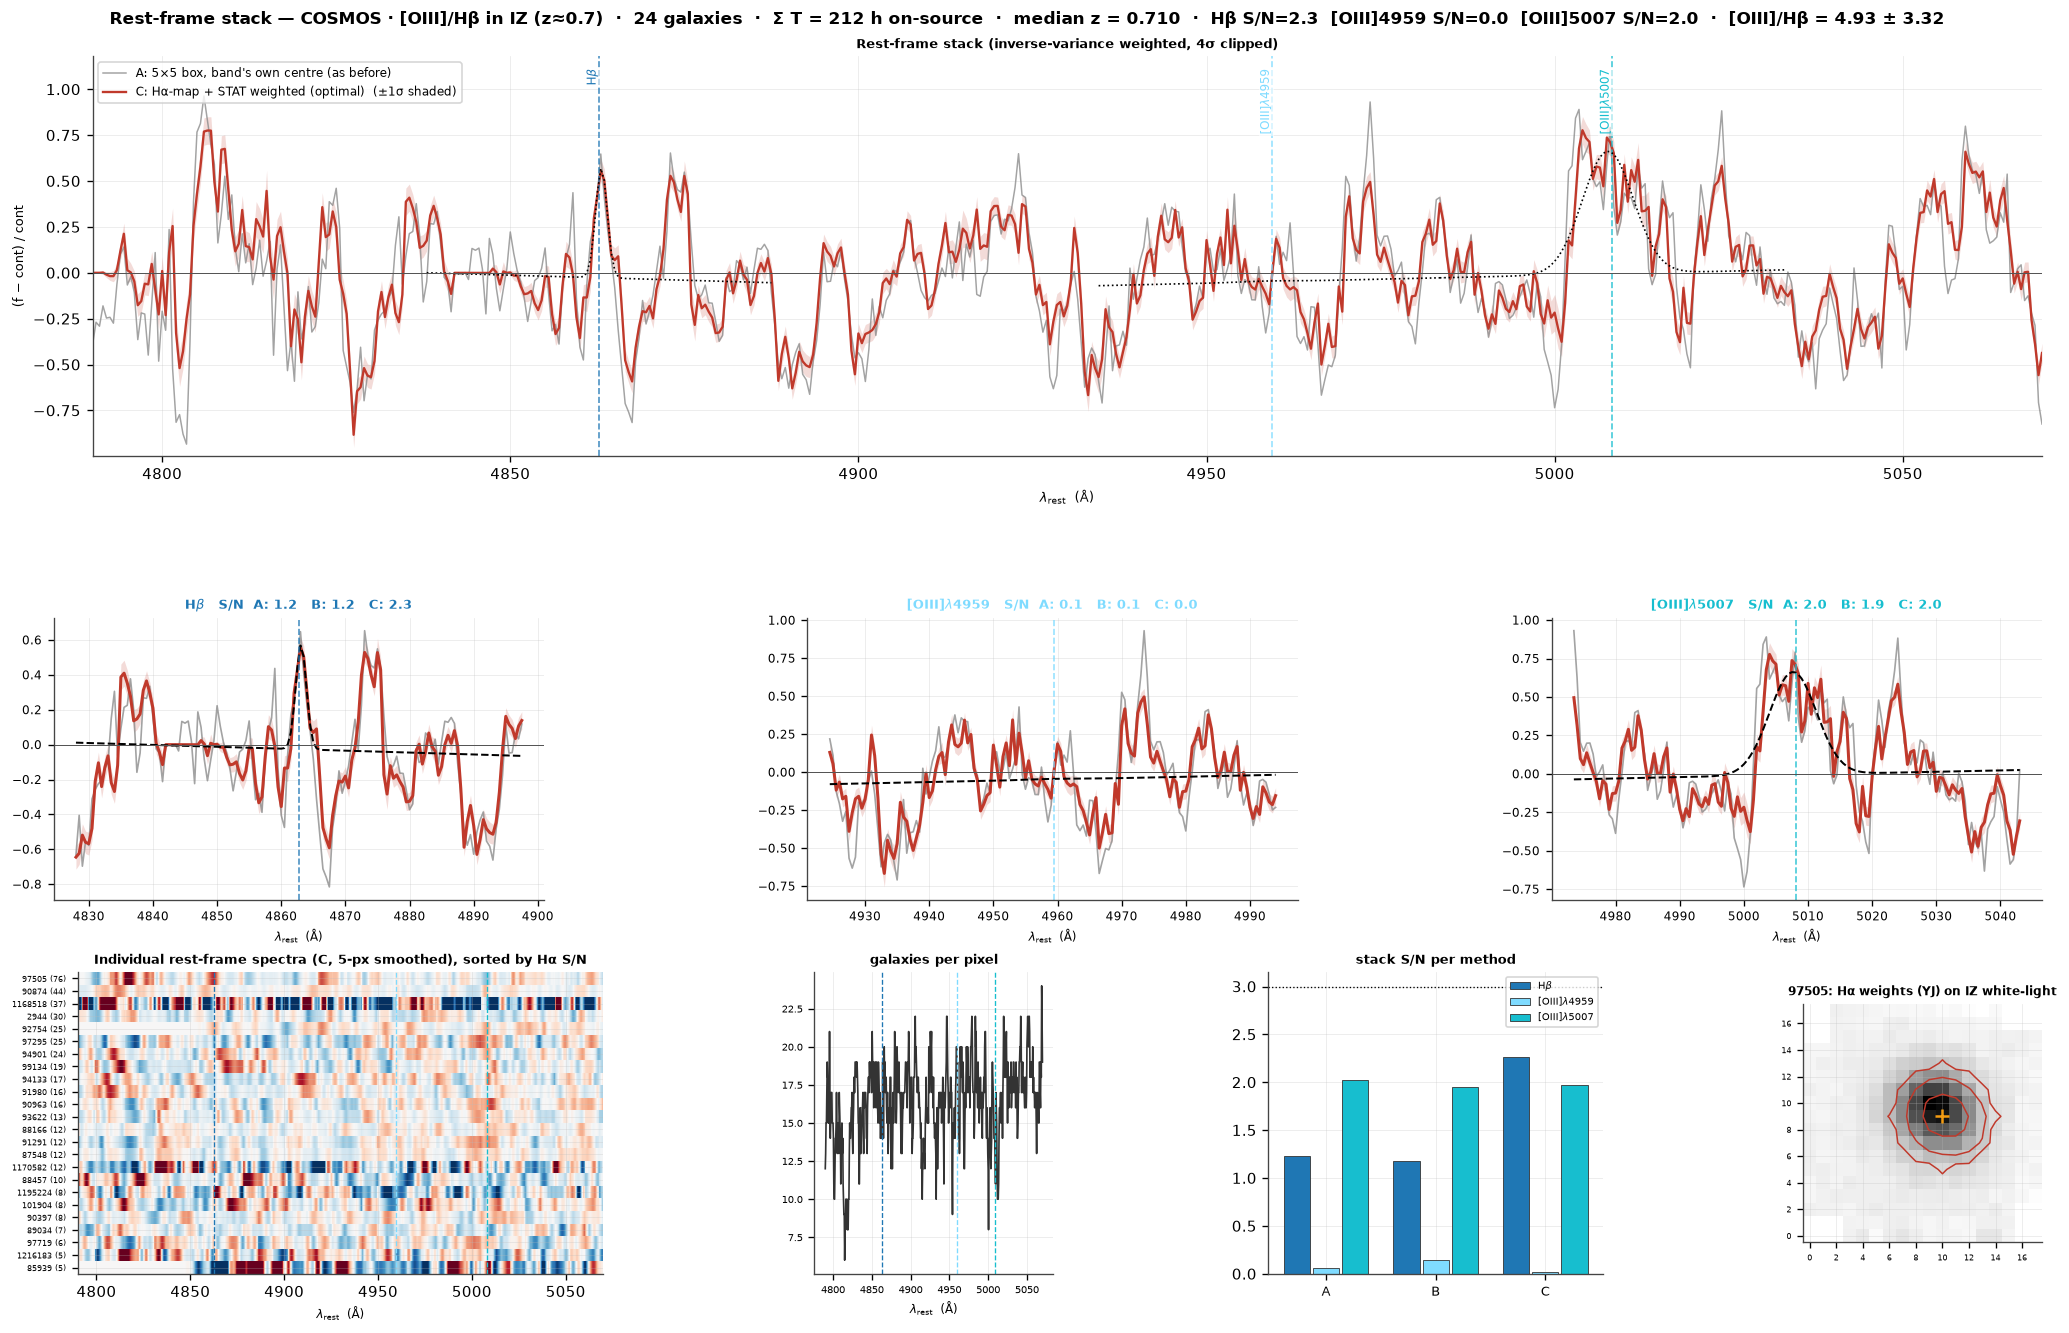

Saved → kmos_restframe_stack_COSMOS_0.pdf


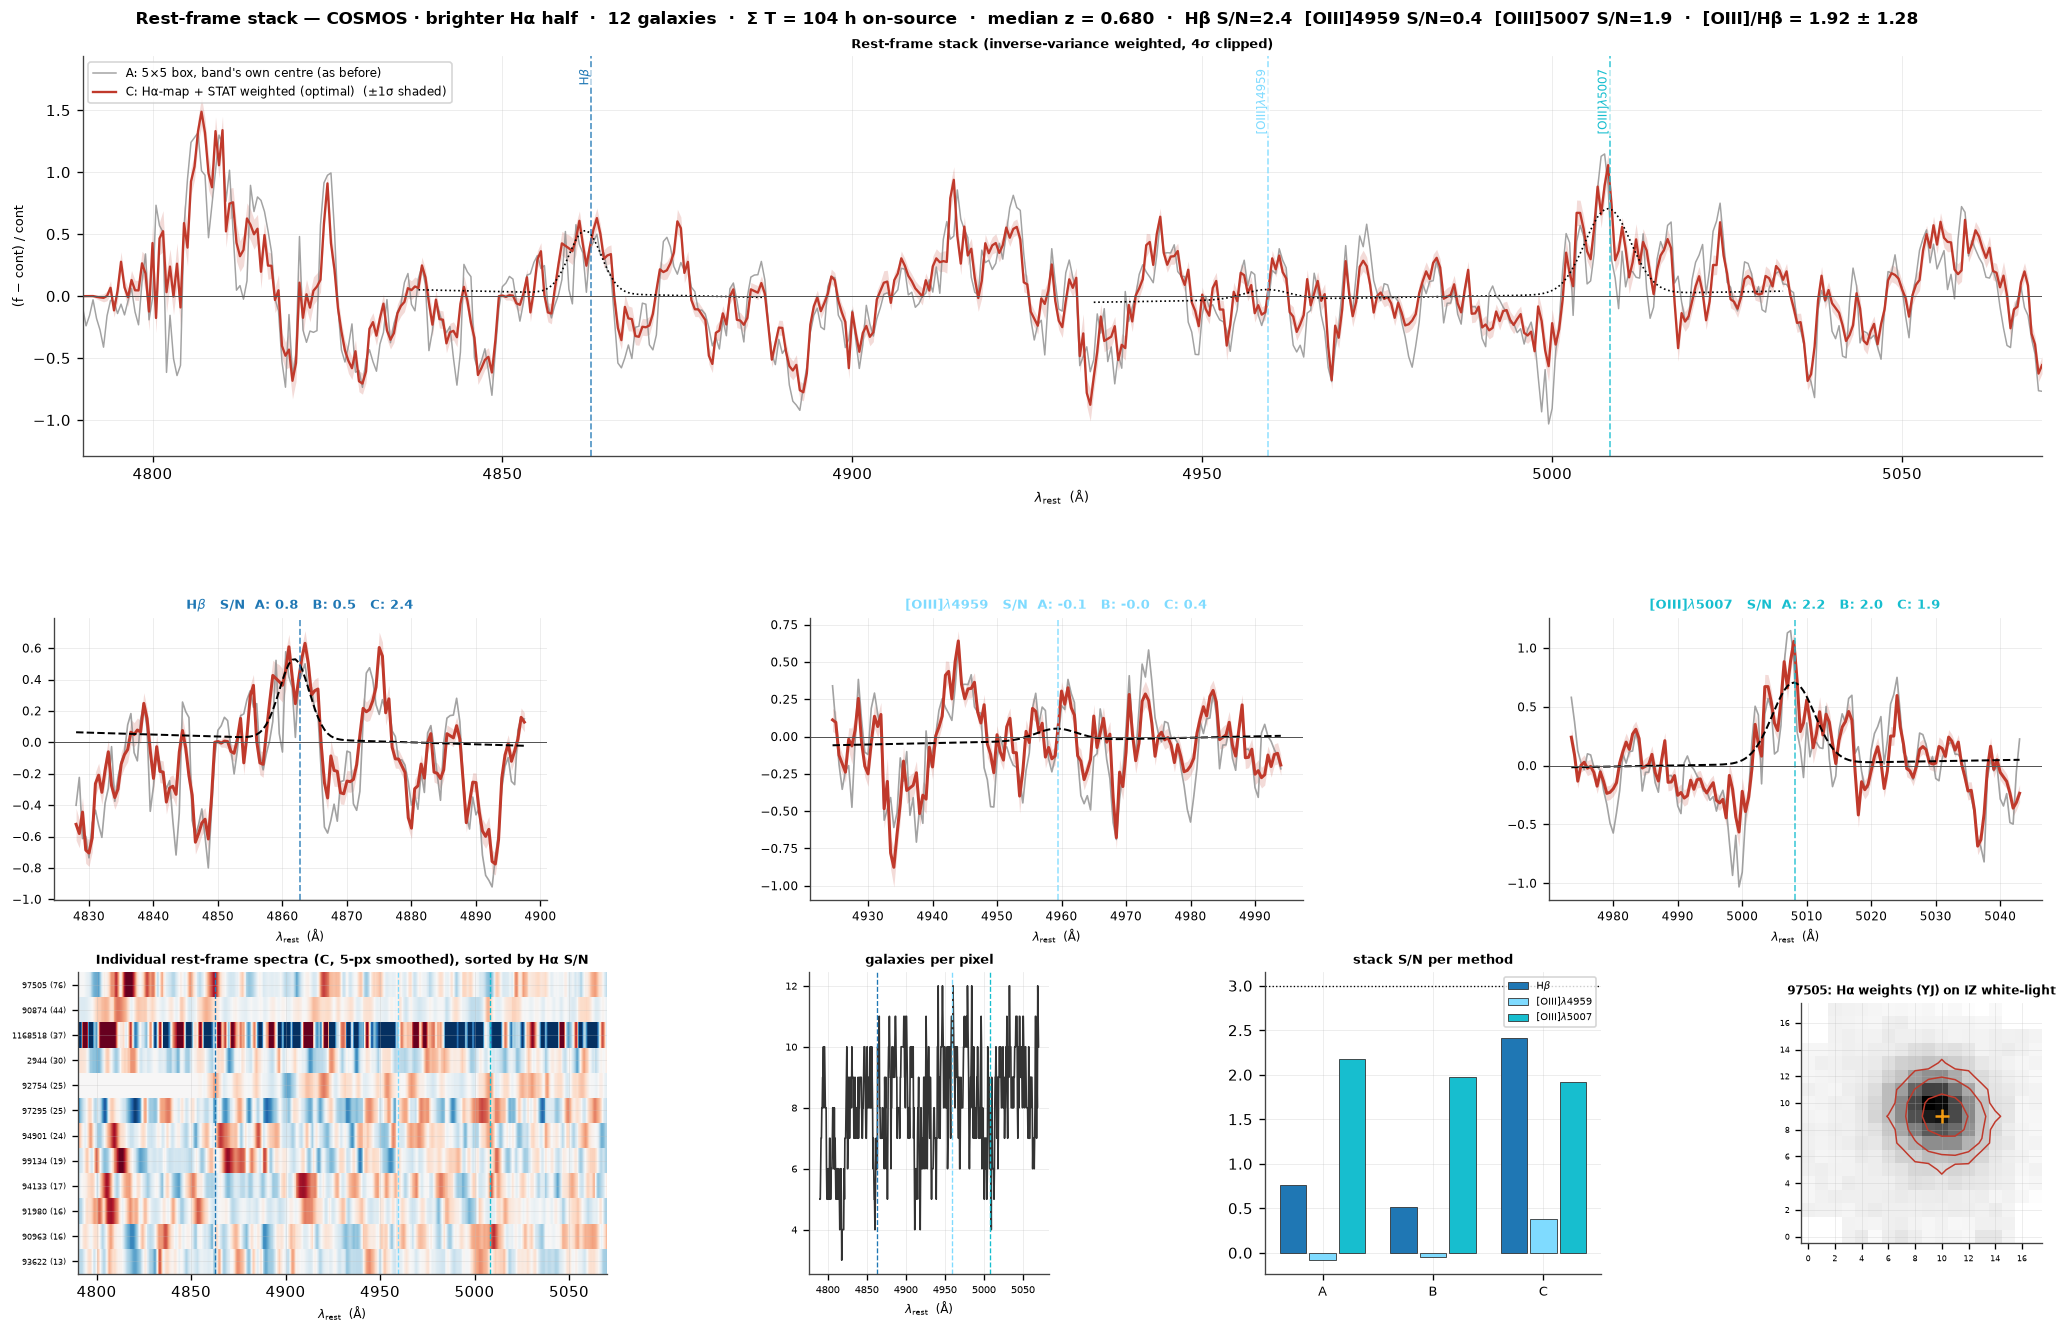

Saved → kmos_restframe_stack_COSMOS_1.pdf


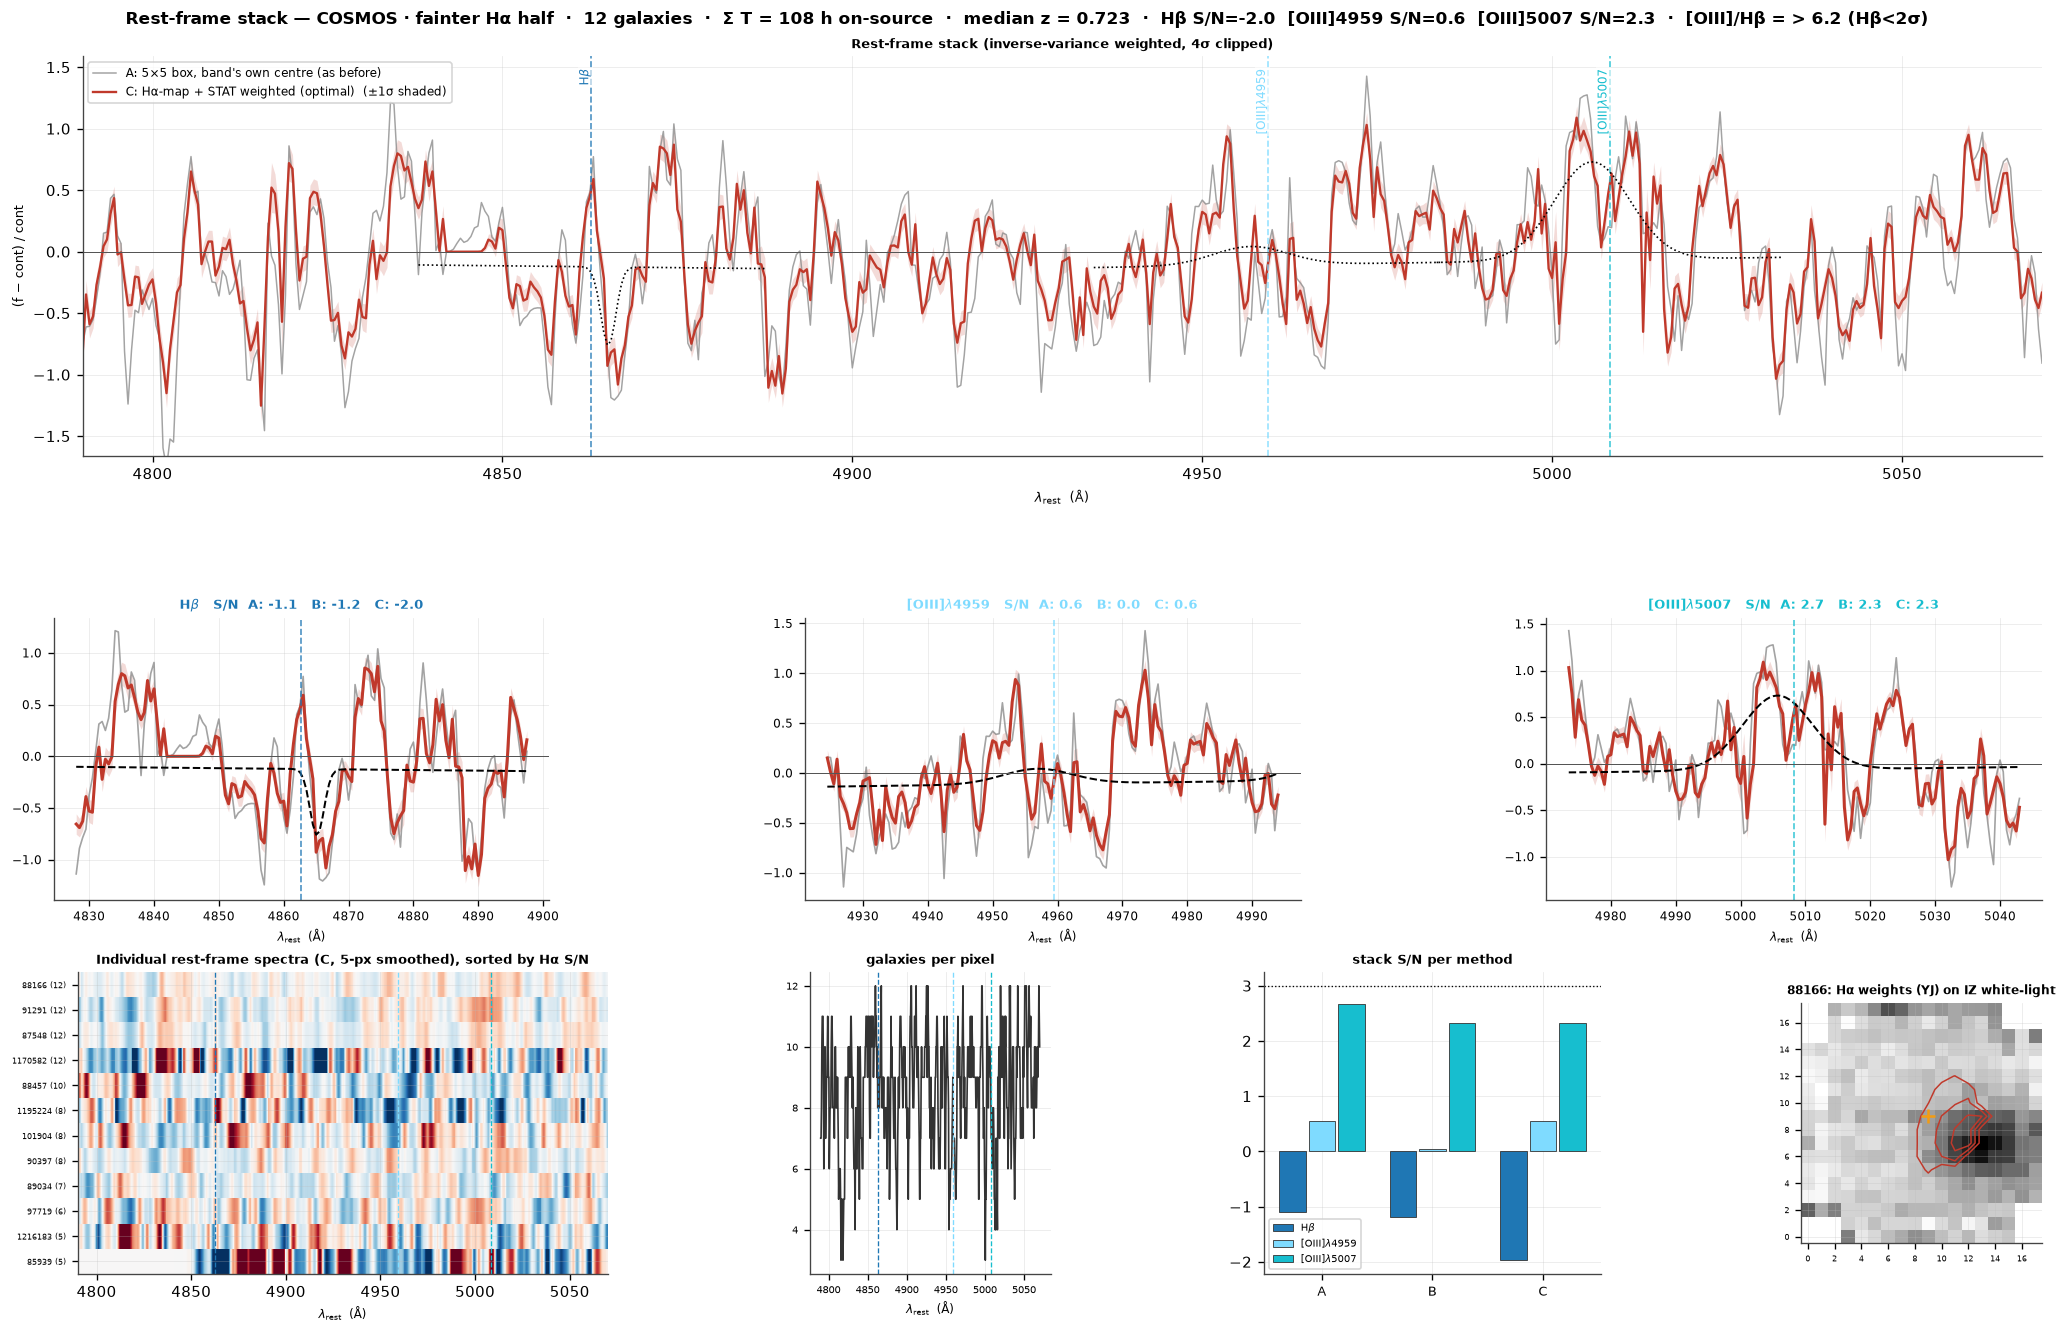

Saved → kmos_restframe_stack_COSMOS_2.pdf


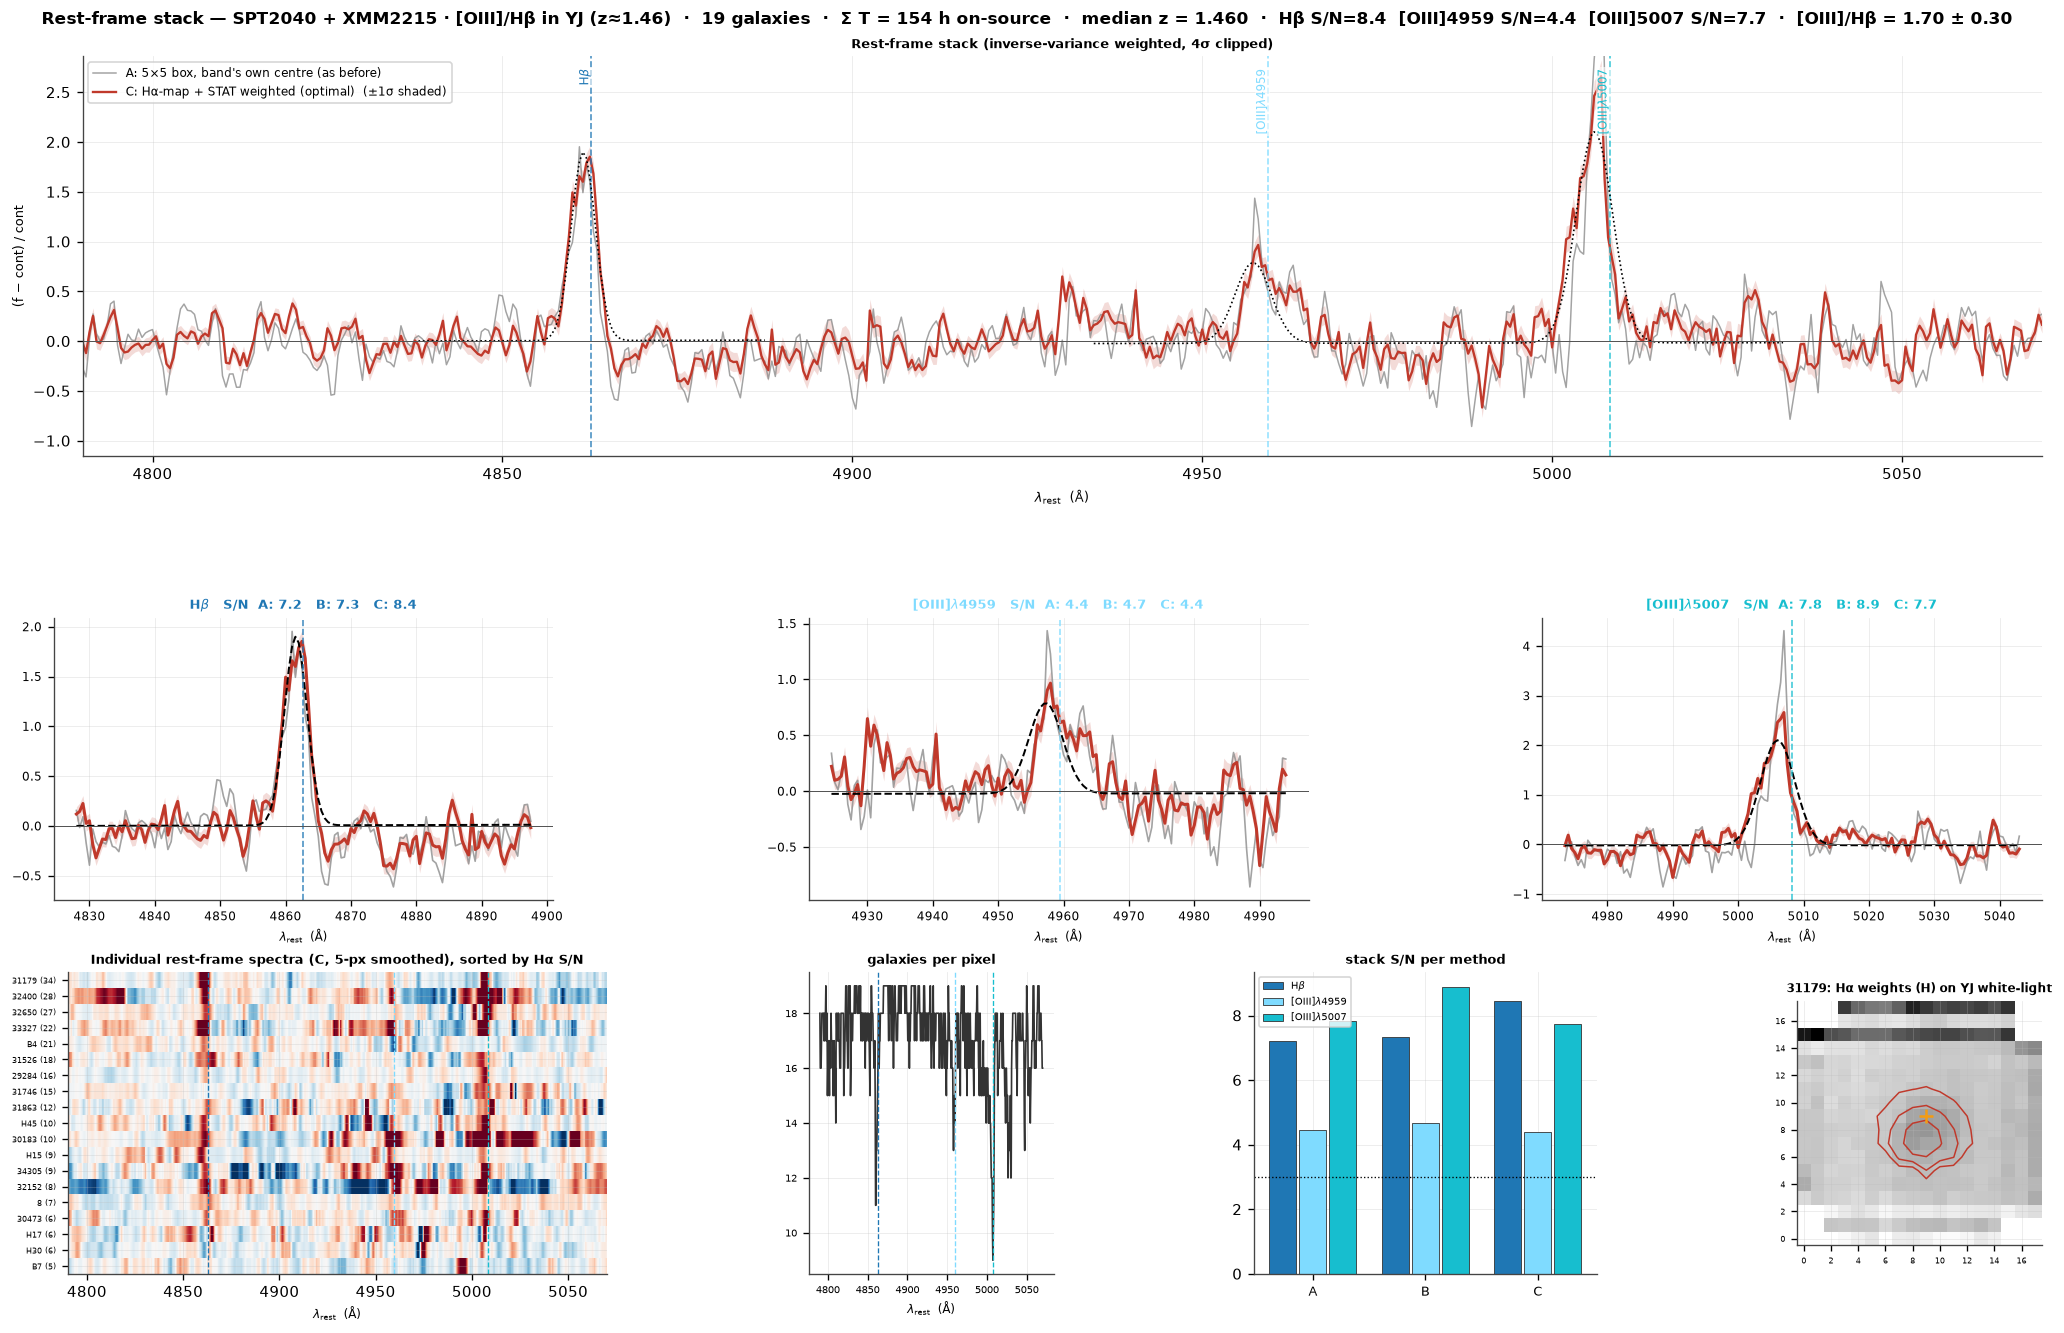

Saved → kmos_restframe_stack_SPT2040___XMM2215_3.pdf


In [11]:
# ── Detail view per sample: stack, line zooms, individual spectra, methods ─────
def _model_curve(fit):
    """Fitted model on the stack (continuum + Gaussians, minus the +1 offset)."""
    return fit.wave, fit.cont + fit.model - 1.0

for si, (name, rows) in enumerate(SAMPLES.items()):
    res = results.get(name, {})
    if 'C' not in res:
        continue
    rc, ra = res['C'], res.get('A')
    t_tot = np.nansum([r['exptime_h'] for r in rows])
    fig = plt.figure(figsize=(17, 11), constrained_layout=True)
    fig.suptitle(
        f"Rest-frame stack — {name}  ·  {rc['N']} galaxies  ·  "
        f"Σ T = {t_tot:.0f} h on-source  ·  median z = {np.median([r['z_ha'] for r in rows]):.3f}  ·  "
        + "  ".join(f"{PLAIN[key]} S/N={rc['fits'][key].snr:.1f}" for key, *_ in STACK_LINES)
        + f"  ·  [OIII]/Hβ = {_ratio(rc['fits']['oiii'], rc['fits']['hb'])}",
        fontsize=10, fontweight='bold')
    outer = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[1.8, 1.6, 1.7], hspace=0.4)

    # ── Row 0: full rest-frame stack ──────────────────────────────────────────
    ax = fig.add_subplot(outer[0])
    x = REST_GRID * 1e4
    if ra is not None:
        ax.plot(x, ra['m'], color=METHODS['A'][1], lw=0.9, alpha=0.8, label=f"A: {METHODS['A'][0]}")
    ax.fill_between(x, rc['m'] - rc['err'], rc['m'] + rc['err'], color=METHODS['C'][1], alpha=0.18, lw=0)
    ax.plot(x, rc['m'], color=METHODS['C'][1], lw=1.4, label=f"C: {METHODS['C'][0]}  (±1σ shaded)")
    for key, lbl, lr, lc in STACK_LINES:
        ax.axvline(lr * 1e4, color=lc, ls='--', lw=1.0, alpha=0.8)
        ax.text(lr * 1e4, 0.97, lbl, transform=ax.get_xaxis_transform(), rotation=90, ha='right',
                va='top', fontsize=7, color=lc, bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
        wv, mv = _model_curve(rc['fits'][key])
        sel = np.abs(wv - lr) < 0.0025
        ax.plot(wv[sel] * 1e4, mv[sel], color='k', lw=1.0, ls=':')
    fin = rc['m'][np.isfinite(rc['m'])]
    if fin.size:
        lo, hi = np.nanpercentile(fin, 1), np.nanpercentile(fin, 99.5)
        ax.set_ylim(lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo))
    ax.axhline(0, color='#555', lw=0.6)
    ax.set_xlim(x[0], x[-1])
    ax.set_xlabel(r'$\lambda_{\rm rest}$  (Å)', fontsize=8)
    ax.set_ylabel('(f − cont) / cont', fontsize=8)
    ax.set_title('Rest-frame stack (inverse-variance weighted, 4σ clipped)', fontsize=8)
    ax.legend(fontsize=7, loc='upper left', framealpha=0.8)

    # ── Row 1: line zooms, A vs C, with fits ──────────────────────────────────
    inner = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[1], wspace=0.3)
    for ci, (key, lbl, lr, lc) in enumerate(STACK_LINES):
        ax = fig.add_subplot(inner[ci])
        sel = np.abs(REST_GRID - lr) < 0.0035
        if ra is not None:
            ax.plot(x[sel], ra['m'][sel], color=METHODS['A'][1], lw=1.0, alpha=0.8)
        ax.fill_between(x[sel], (rc['m'] - rc['err'])[sel], (rc['m'] + rc['err'])[sel],
                        color=METHODS['C'][1], alpha=0.18, lw=0)
        ax.plot(x[sel], rc['m'][sel], color=METHODS['C'][1], lw=1.8)
        wv, mv = _model_curve(rc['fits'][key])
        s2 = np.abs(wv - lr) < 0.0035
        ax.plot(wv[s2] * 1e4, mv[s2], color='k', lw=1.2, ls='--', label='fit (C)')
        ax.axvline(lr * 1e4, color=lc, ls='--', lw=1.0, alpha=0.8)
        ax.axhline(0, color='#555', lw=0.6)
        snr_txt = "   ".join(f"{k}: {res[k]['fits'][key].snr:.1f}" for k in 'ABC' if k in res)
        ax.set_title(f"{lbl}   S/N  {snr_txt}", fontsize=8, color=lc)
        ax.set_xlabel(r'$\lambda_{\rm rest}$  (Å)', fontsize=7)
        ax.tick_params(labelsize=7)

    # ── Row 2: individual spectra, coverage, methods, example weight map ─────
    inner2 = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[2], wspace=0.35,
                                              width_ratios=[2.2, 1.0, 1.4, 1.0])
    ax = fig.add_subplot(inner2[0])
    srt = sorted([r for r in rows if r['rest'].get('C') is not None], key=lambda r: -r['snr_ha'])
    img = np.array([uniform_filter(np.nan_to_num(r['rest']['C'][0]), 5) for r in srt])
    if img.size:
        v = np.nanpercentile(np.abs(img), 97)
        ax.imshow(img, aspect='auto', cmap='RdBu_r', vmin=-v, vmax=v, interpolation='nearest',
                  extent=[x[0], x[-1], len(srt) - 0.5, -0.5])
        for _, _, lr, lc in STACK_LINES:
            ax.axvline(lr * 1e4, color=lc, ls='--', lw=0.8)
        ax.set_yticks(range(len(srt)))
        ax.set_yticklabels([f"{r['tid']} ({r['snr_ha']:.0f})" for r in srt], fontsize=5)
    ax.set_title('Individual rest-frame spectra (C, 5-px smoothed), sorted by Hα S/N', fontsize=8)
    ax.set_xlabel(r'$\lambda_{\rm rest}$  (Å)', fontsize=7)

    ax = fig.add_subplot(inner2[1])
    ax.plot(x, rc['n'], color='#333', lw=1.0)
    for _, _, lr, lc in STACK_LINES:
        ax.axvline(lr * 1e4, color=lc, ls='--', lw=0.8)
    ax.set_title('galaxies per pixel', fontsize=8); ax.tick_params(labelsize=6)
    ax.set_xlabel(r'$\lambda_{\rm rest}$  (Å)', fontsize=7)

    ax = fig.add_subplot(inner2[2])
    bw = 0.8 / len(STACK_LINES); xs = np.arange(len(METHODS))
    for li, (key, lbl, _, lc) in enumerate(STACK_LINES):
        vals = [res[k]['fits'][key].snr if k in res else 0 for k in METHODS]
        ax.bar(xs + (li - 1) * bw, vals, bw * 0.9, color=lc, edgecolor='#333', lw=0.5, label=lbl)
    ax.axhline(3, color='k', ls=':', lw=0.8)
    ax.set_xticks(xs); ax.set_xticklabels(list(METHODS), fontsize=8)
    ax.set_title('stack S/N per method', fontsize=8); ax.legend(fontsize=6)

    ax = fig.add_subplot(inner2[3])
    ex = srt[0] if srt else None
    if ex is not None and ex['W_tgt'] is not None:
        ax.imshow(ex['wl_tgt'], origin='lower', cmap='Greys', aspect='equal')
        ax.contour(ex['W_tgt'], levels=np.nanmax(ex['W_tgt']) * np.array([0.2, 0.5, 0.8]),
                   colors=METHODS['C'][1], linewidths=0.9)
        ax.plot(ex['ctr_tgt'][1], ex['ctr_tgt'][0], '+', color='#f39c12', ms=8, mew=1.5)
        ax.set_title(f"{ex['tid']}: Hα weights ({ex['ha_band']}) on {ex['band']} white-light",
                     fontsize=7)
    ax.tick_params(labelsize=5)

    fname = "kmos_restframe_stack_" + "".join(c if c.isalnum() else "_" for c in name.split('·')[0].strip()) \
            + f"_{si}.pdf"
    plt.savefig(fname, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")

## Summary

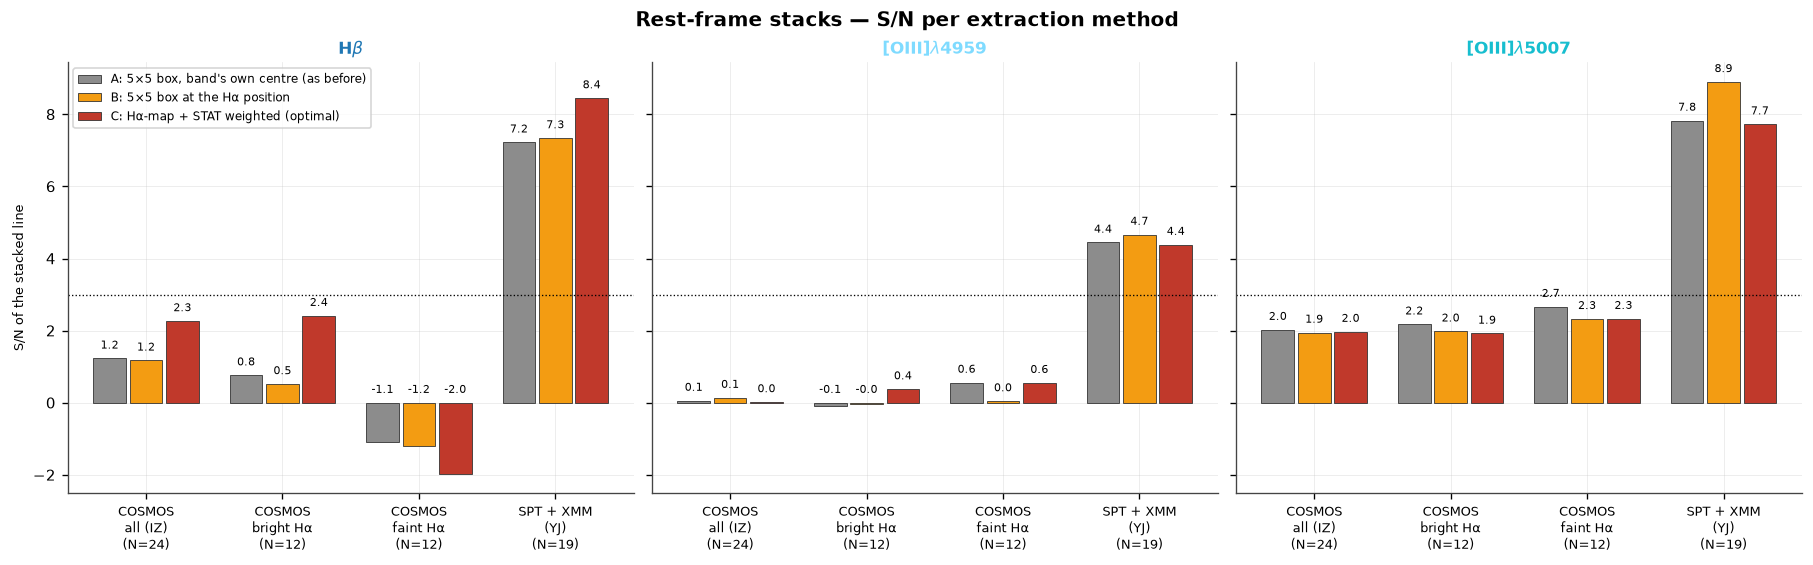

Saved → kmos_restframe_stack_summary.pdf


In [12]:
# ── Summary: S/N per method and sample ─────────────────────────────────────────
names = [n for n in SAMPLES if results.get(n)]
fig, axes = plt.subplots(1, len(STACK_LINES), figsize=(15, 4.6), constrained_layout=True, sharey=True)
fig.suptitle("Rest-frame stacks — S/N per extraction method", fontsize=12, fontweight='bold')
bw = 0.8 / len(METHODS)
for ax, (key, lbl, _, lc) in zip(axes, STACK_LINES):
    xs = np.arange(len(names))
    for mi, (k, (mlabel, mc)) in enumerate(METHODS.items()):
        vals = [results[n][k]['fits'][key].snr if k in results[n] else np.nan for n in names]
        bars = ax.bar(xs + (mi - 1) * bw, vals, bw * 0.9, color=mc, edgecolor='#333', lw=0.5,
                      label=f"{k}: {mlabel}")
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.text(b.get_x() + b.get_width() / 2, max(v, 0) + 0.2, f"{v:.1f}",
                        ha='center', va='bottom', fontsize=6.5)
    ax.axhline(3, color='k', ls=':', lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{SAMPLE_SHORT.get(n, n)}\n(N={results[n]['C']['N'] if 'C' in results[n] else 0})"
                        for n in names], fontsize=7.5)
    ax.set_title(lbl, color=lc, fontsize=10)
axes[0].set_ylabel('S/N of the stacked line')
axes[0].legend(fontsize=7, loc='upper left')
plt.savefig("kmos_restframe_stack_summary.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_restframe_stack_summary.pdf")

## Gallery — per galaxy



Saved → kmos_restframe_stack_gallery.pdf


In [13]:
# ── Gallery: per galaxy — Hα weight map and rest-frame [OIII]/Hβ (A vs C) ──────
rows_g = sorted(stack_rows, key=lambda r: (r['field'] != 'COSMOS', -r['snr_ha']))
n = len(rows_g)
fig, axes = plt.subplots(n, 4, figsize=(17, n * 2.3), constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[0.7, 0.7, 1.6, 1.6]))
if n == 1:
    axes = axes[np.newaxis, :]
fig.suptitle(f"Per-galaxy [OIII]/Hβ after optimal extraction — {n} galaxies "
             f"(grey = A: box at own centre, red = C: Hα-map + STAT weighted; z from Hα)",
             fontsize=11, fontweight='bold', y=1.002)
zooms = [('Hβ', 0.48627, 0.0030), ('[OIII]4959 + 5007', 0.4984, 0.0050)]
for ri, r in enumerate(rows_g):
    ax = axes[ri, 0]
    if r['W_ha'] is not None:
        ax.imshow(r['W_ha'], origin='lower', cmap='inferno', aspect='equal')
    ax.set_title(f"Hα map ({r['ha_band']})", fontsize=6.5, pad=2); ax.tick_params(labelsize=5)
    ax.set_ylabel(f"{r['field']} {r['tid']}\nz={r['z_ha']:.4f}  Hα={r['snr_ha']:.0f}\n"
                  f"{r['band']} {r['exptime_h']:.1f} h", fontsize=6.5)
    ax = axes[ri, 1]
    ax.imshow(r['wl_tgt'], origin='lower', cmap='Greys', aspect='equal')
    if r['W_tgt'] is not None:
        ax.contour(r['W_tgt'], levels=np.nanmax(r['W_tgt']) * np.array([0.2, 0.5, 0.8]),
                   colors=METHODS['C'][1], linewidths=0.7)
    ax.set_title(f"weights on {r['band']}", fontsize=6.5, pad=2); ax.tick_params(labelsize=5)
    for zi, (zl, zc, zh) in enumerate(zooms):
        ax = axes[ri, 2 + zi]
        sel = np.abs(REST_GRID - zc) < zh
        for k, lw in (('A', 0.9), ('C', 1.4)):
            if r['rest'].get(k) is not None:
                ax.plot(REST_GRID[sel] * 1e4, uniform_filter(np.nan_to_num(r['rest'][k][0]), 3)[sel],
                        color=METHODS[k][1], lw=lw)
        for key, lbl, lr, lc in STACK_LINES:
            if abs(lr - zc) < zh:
                ax.axvline(lr * 1e4, color=lc, ls='--', lw=0.9)
        ax.axhline(0, color='#555', lw=0.5)
        keys = ['hb'] if zi == 0 else ['oiii4', 'oiii']
        txt = "   ".join(f"{k}:" + "/".join(f"{r['snr_ind'].get((k, kk), np.nan):.1f}" for kk in keys)
                         for k in 'AC')
        ax.set_title(f"{zl}   S/N {txt}", fontsize=6.5, pad=2)
        ax.tick_params(labelsize=5)
        if ri == n - 1:
            ax.set_xlabel(r'$\lambda_{\rm rest}$  (Å)', fontsize=7)
plt.savefig("kmos_restframe_stack_gallery.pdf", bbox_inches='tight')
plt.show()
print("Saved → kmos_restframe_stack_gallery.pdf")